<a href="https://colab.research.google.com/github/Manas-Siddharth/Deep-Learning/blob/main/binary_cnn_cats_dogs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# New Section

In [1]:
!pip install -q datasets


README.md:   0%|          | 0.00/2.03k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/753 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  182MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 45.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Training images: (8000, 150, 150, 3)
Testing images: (2000, 150, 150, 3)


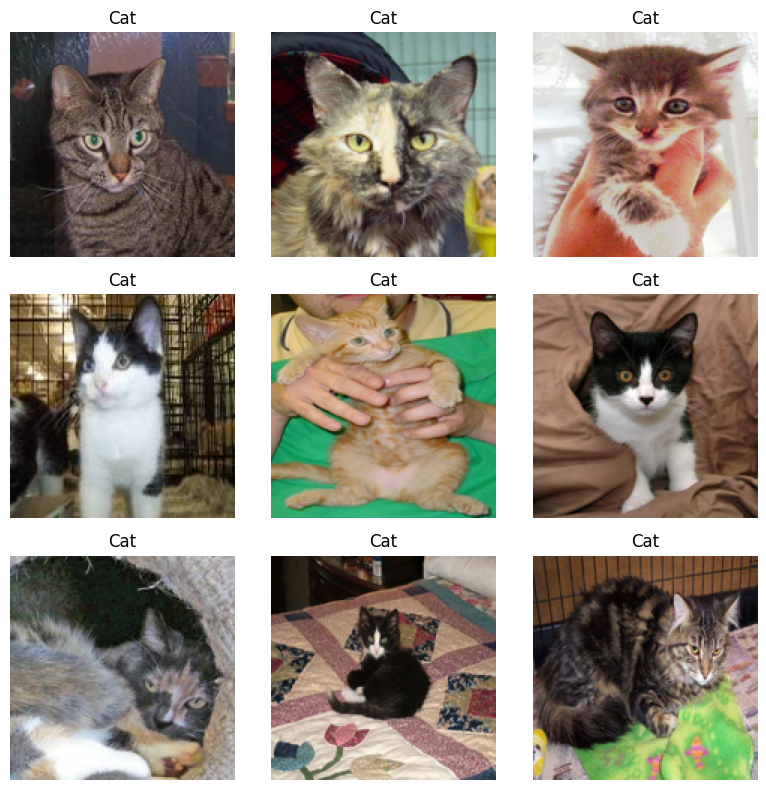

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 23s 34ms/step - accuracy: 0.7139 - loss: 0.6036 - val_accuracy: 0.0250 - val_loss: 1.2688
Epoch 2/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.7280 - loss: 0.5504 - val_accuracy: 0.0433 - val_loss: 1.7961
Epoch 3/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.7625 - loss: 0.4917 - val_accuracy: 0.5575 - val_loss: 0.8297
Epoch 4/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8027 - loss: 0.4311 - val_accuracy: 0.6129 - val_loss: 0.7551
Epoch 5/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.8409 - loss: 0.3621 - val_accuracy: 0.5567 - val_loss: 1.0357
Epoch 6/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8918 - loss: 0.2633 - val_accuracy: 0.5171 - val_loss: 1.2929
Epoch 7/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9375 - loss: 0.1587 - val_accuracy: 0.5417 - val_loss: 1.8764
Epoch 8/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9670 - loss: 0.0915 - val_ac

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from datasets import load_dataset
from tensorflow.keras import layers, models

dataset = load_dataset("Bingsu/Cat_and_Dog")

train_hf = dataset["train"]
test_hf = dataset["test"]

IMG_SIZE = (150, 150)
BATCH_SIZE = 16

def preprocess(example):
    image = example["image"].convert("RGB")
    image = image.resize(IMG_SIZE)
    image = np.array(image, dtype=np.float32) / 255.0
    return image

x_train = np.array([preprocess(x) for x in train_hf])
y_train = np.array(train_hf["labels"])

x_test = np.array([preprocess(x) for x in test_hf])
y_test = np.array(test_hf["labels"])

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title("Cat" if y_train[i] == 0 else "Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(150, 150, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=BATCH_SIZE,
    validation_split=0.3
)

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    batch_size=BATCH_SIZE
)

print("\nFinal Results")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)



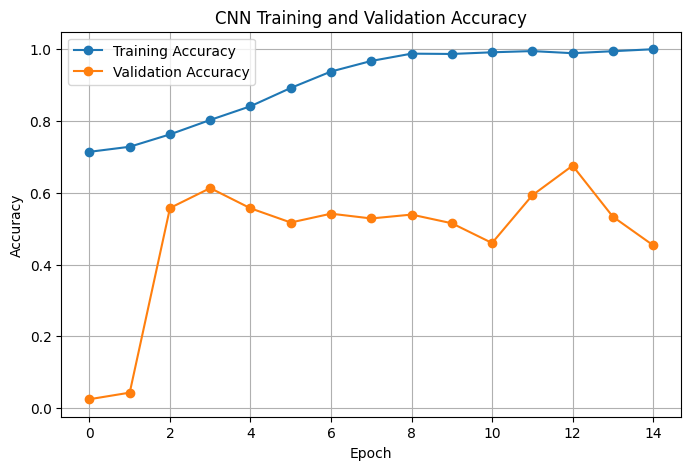

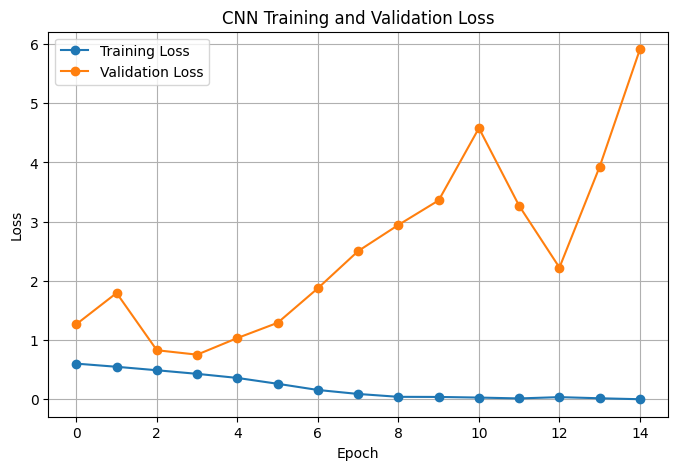

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


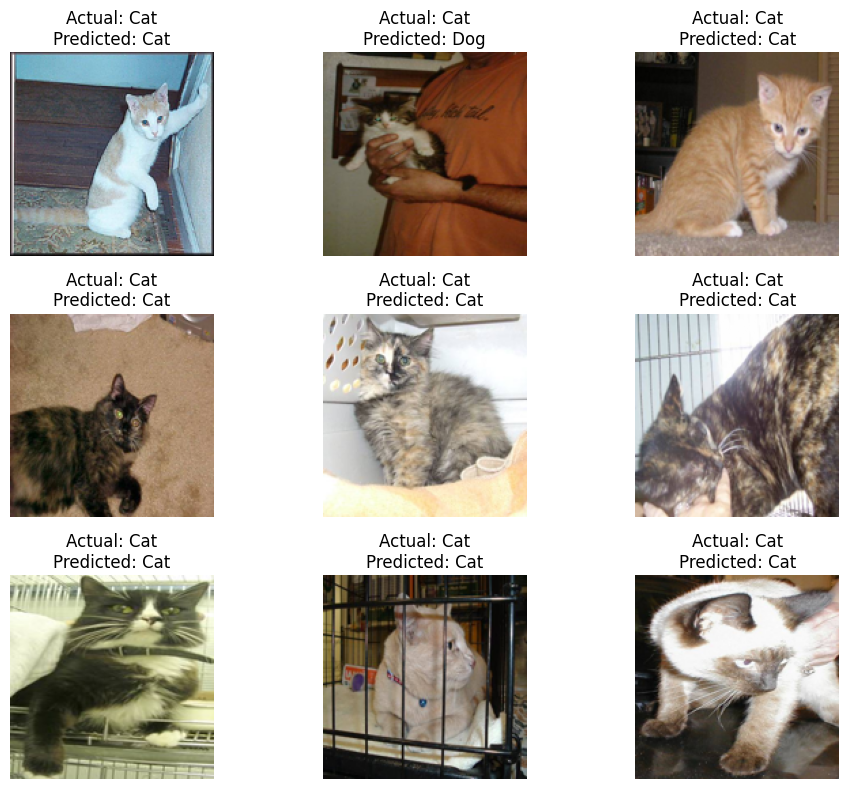

In [3]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

predictions = model.predict(x_test[:9])

plt.figure(figsize=(10, 8))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(x_test[i])

    predicted = "Dog" if predictions[i][0] >= 0.5 else "Cat"
    actual = "Dog" if y_test[i] == 1 else "Cat"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()